Ingresa los valores de x y f(x):

Tabla de diferencias divididas:
i    x_i       f[x_i]         f[x_{i-1},...,x_{i}]f[x_{i-2},...,x_{i}]
0    1.0000    8.0000000      -7.0000000     3.0000000      
1    2.0000    1.0000000      2.0000000      
2    4.0000    5.0000000      

El polinomio interpolado de Newton es:
3.0*x**2 - 16.0*x + 21.0


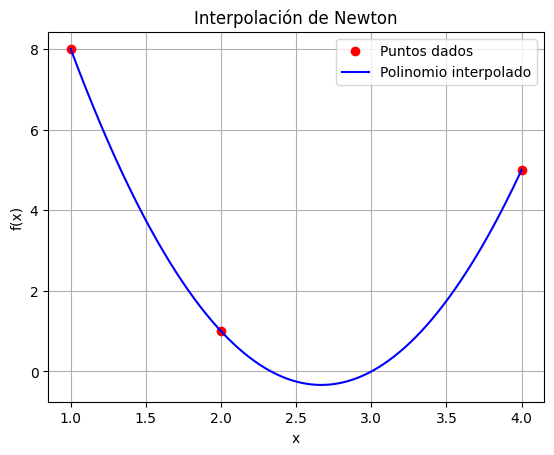

In [ ]:
#polinomios de Newton
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

# Función para calcular las diferencias divididas de Newton
def diferencias_divididas(x, y):
    n = len(x)
    tabla = np.zeros((n, n))
    tabla[:, 0] = y  # Primera columna son los valores de y

    for j in range(1, n):
        for i in range(n - j):
            denominador = x[i + j] - x[i]
            if denominador == 0:
                print(f"Error: Se encontraron valores de x iguales en x[{i}] = x[{i+j}] = {x[i]}")
                return None
            tabla[i, j] = (tabla[i + 1, j - 1] - tabla[i, j - 1]) / denominador

    return tabla

# Función para construir el polinomio de Newton simbólicamente
def construir_polinomio_simb(tabla, x):
    n = len(x)
    x_simb = sp.symbols('x')
    polinomio = tabla[0, 0]
    producto = 1

    # Generar el polinomio de Newton
    for i in range(1, n):
        producto *= (x_simb - x[i - 1])
        polinomio += producto * tabla[0, i]

    polinomio_simplificado = sp.simplify(polinomio)
    return polinomio_simplificado

# Función para mostrar la tabla de diferencias divididas ordenadamente
def mostrar_tabla_diferencias(tabla, x):
    n = len(x)
    print(f"{'i':<5}{'x_i':<10}{'f[x_i]':<15}", end='')
    for j in range(1, n):
        print(f"f[x_{{i-{j}}},...,x_{{i}}]".center(15), end='')
    print()

    for i in range(n):
        print(f"{i:<5}{x[i]:<10.4f}{tabla[i, 0]:<15.7f}", end='')
        for j in range(1, n - i):
            print(f"{tabla[i, j]:<15.7f}", end='')
        print()

# Ingresar los valores de x y f(x)
n = int(input("¿Cuántos puntos x_i hay? "))
x = np.zeros(n)
y = np.zeros(n)

print("Ingresa los valores de x y f(x):")
for i in range(n):
    x[i] = float(input(f"x_{i}: "))
    y[i] = float(input(f"f(x_{i}): "))

# Calcular la tabla de diferencias divididas
tabla_diferencias = diferencias_divididas(x, y)

if tabla_diferencias is not None:
    # Mostrar la tabla de diferencias divididas ordenadamente
    print("\nTabla de diferencias divididas:")
    mostrar_tabla_diferencias(tabla_diferencias, x)

    # Construir y mostrar el polinomio de Newton simbólicamente
    polinomio_simb = construir_polinomio_simb(tabla_diferencias, x)
    print("\nEl polinomio interpolado de Newton es:")
    print(polinomio_simb)

    # Evaluar el polinomio en puntos intermedios para graficar
    x_interp = np.linspace(min(x), max(x), 500)
    y_interp = [polinomio_newton(tabla_diferencias, x, xi) for xi in x_interp]

    # Graficar los puntos y el polinomio interpolado
    plt.plot(x, y, 'ro', label='Puntos dados')
    plt.plot(x_interp, y_interp, 'b-', label='Polinomio interpolado')
    plt.title('Interpolación de Newton')
    plt.xlabel('x')
    plt.ylabel('f(x)')
    plt.legend()
    plt.grid(True)
    plt.show()

    # Evaluar el polinomio en un valor específico de x
    x_val = float(input("\nIntroduce el valor de x para evaluar f(x): "))
    f_val = polinomio_newton(tabla_diferencias, x, x_val)
    print(f"f({x_val}) = {f_val:.4f}")
else:
    print("No se pudo calcular la tabla de diferencias divididas debido a un error.")




¿Cuántos puntos x_i hay?: 3
Ingrese el valor de x[0]: 1
Ingrese el valor de f(x[0]): 8
Ingrese el valor de x[1]: 2
Ingrese el valor de f(x[1]): 1
Ingrese el valor de x[2]: 4
Ingrese el valor de f(x[2]): 5

Tabla de diferencias divididas:
f[x[0], ..., x[2]] = 8.0
f[x[1], ..., x[2]] = -7.0
f[x[2], ..., x[2]] = 3.0


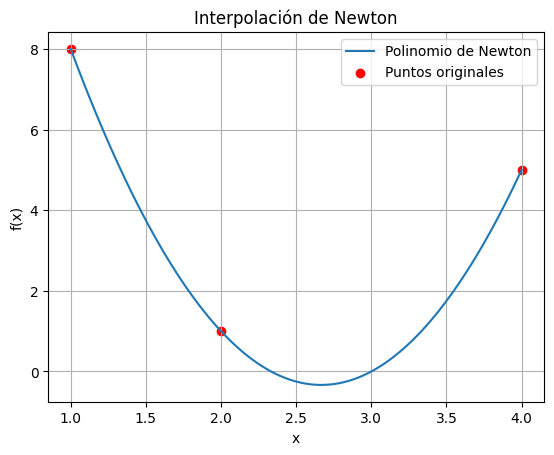

¿Te gustaría calcular f(x) o encontrar x dado f(x)? (Escribe 'f(x)' o 'x'): x
Ingresa el valor de f(x) que deseas: 0
El valor de x que corresponde a f(x) = 0.0 es aproximadamente 2.3333333333333335


In [ ]:
#(puedes calcular inversos)
import numpy as np
import matplotlib.pyplot as plt

# Función para calcular las diferencias divididas
def diferencias_divididas(x, y):
    n = len(y)
    coef = np.zeros([n, n])
    coef[:,0] = y  # Primer columna es y
    for j in range(1, n):
        for i in range(n - j):
            coef[i][j] = (coef[i+1][j-1] - coef[i][j-1]) / (x[i+j] - x[i])
    return coef[0, :]  # Retorna la primera fila (coeficientes del polinomio)

# Función para construir el polinomio de Newton
def newton_polynomial(coef, x_data, x):
    n = len(x_data) - 1
    p = coef[n]
    for k in range(1, n + 1):
        p = coef[n - k] + (x - x_data[n - k]) * p
    return p

# Pedir al usuario los puntos
n = int(input("¿Cuántos puntos x_i hay?: "))

x = np.zeros(n)
y = np.zeros(n)

for i in range(n):
    x[i] = float(input(f"Ingrese el valor de x[{i}]: "))
    y[i] = float(input(f"Ingrese el valor de f(x[{i}]): "))

# Calcular las diferencias divididas
coef = diferencias_divididas(x, y)

# Mostrar tabla de diferencias divididas
print("\nTabla de diferencias divididas:")
for i in range(n):
    print(f"f[x[{i}], ..., x[{n-1}]] = {coef[i]}")

# Graficar los puntos originales
x_vals = np.linspace(min(x), max(x), 100)
y_vals = [newton_polynomial(coef, x, val) for val in x_vals]

plt.plot(x_vals, y_vals, label="Polinomio de Newton")
plt.scatter(x, y, color='red', label="Puntos originales")
plt.title("Interpolación de Newton")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.legend()
plt.grid(True)
plt.show()

# Preguntar al usuario si desea calcular un f(x) o un x dado f(x)
opcion = input("¿Te gustaría calcular f(x) o encontrar x dado f(x)? (Escribe 'f(x)' o 'x'): ")

if opcion == "f(x)":
    x_val = float(input("Ingresa el valor de x: "))
    f_val = newton_polynomial(coef, x, x_val)
    print(f"f({x_val}) = {f_val}")
elif opcion == "x":
    f_deseado = float(input("Ingresa el valor de f(x) que deseas: "))
    from scipy.optimize import fsolve
    # Definir la función para resolver f(x) = y
    def polinomio_inverso(x_val):
        return newton_polynomial(coef, x, x_val) - f_deseado
    # Usar fsolve para encontrar el valor de x
    x_sol = fsolve(polinomio_inverso, x[0])  # Usa el primer valor de x como estimación inicial
    print(f"El valor de x que corresponde a f(x) = {f_deseado} es aproximadamente {x_sol[0]}")
else:
    print("Opción no válida. Intenta de nuevo.")


¿Cuántos puntos (x_i) quieres ingresar? 4
Ingrese x_0: 0
Ingrese f(x_0): 2
Ingrese x_1: 1
Ingrese f(x_1): 3
Ingrese x_2: 4
Ingrese f(x_2): 18
Ingrese x_3: 6
Ingrese f(x_3): 38
El polinomio de Lagrange es: x**2 + 2
¿Quieres calcular algún f(x)? (sí/no): sí
Ingrese el valor de x para calcular f(x): 2
f(2) = 6


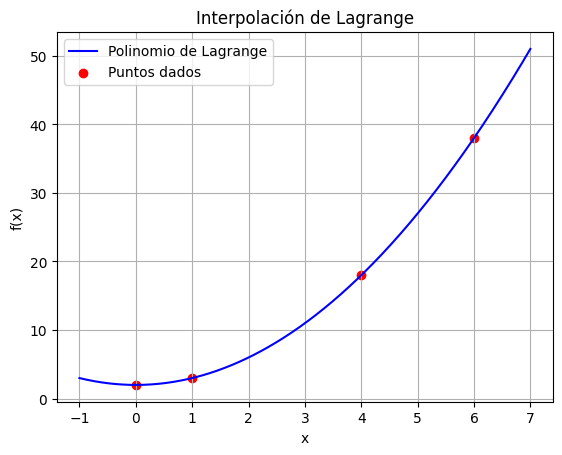

In [ ]:
#Lagrange
import numpy as np
import matplotlib.pyplot as plt
from sympy import symbols, expand, sympify

# Función para calcular el polinomio de Lagrange
def lagrange_interpol(x_values, f_values):
    x = symbols('x')
    n = len(x_values)
    polynomial = 0
    for i in range(n):
        term = f_values[i]
        for j in range(n):
            if i != j:
                term *= (x - x_values[j]) / (x_values[i] - x_values[j])
        polynomial += term
    return expand(polynomial)

# Pedir los puntos al usuario
n = int(input("¿Cuántos puntos (x_i) quieres ingresar? "))

x_values = []
f_values = []

for i in range(n):
    x_i = sympify(input(f"Ingrese x_{i}: "))  # Ingresar como e**1 o exp(1) está permitido
    f_xi = sympify(input(f"Ingrese f(x_{i}): "))  # Ingresar como e**1 o exp(1) también
    x_values.append(x_i)
    f_values.append(f_xi)

# Calcular el polinomio de Lagrange
polinomio = lagrange_interpol(x_values, f_values)
print(f"El polinomio de Lagrange es: {polinomio}")

# Preguntar si se desea calcular un valor de f(x)
calcular = input("¿Quieres calcular algún f(x)? (sí/no): ").strip().lower()
if calcular == "sí":
    x_calcular = sympify(input("Ingrese el valor de x para calcular f(x): "))
    f_calculado = polinomio.subs('x', x_calcular)
    print(f"f({x_calcular}) = {f_calculado}")

# Graficar el polinomio y los puntos dados
x_vals = np.linspace(float(min(x_values)) - 1, float(max(x_values)) + 1, 500)
f_lagrange = np.array([float(polinomio.subs('x', val)) for val in x_vals])

plt.plot(x_vals, f_lagrange, label='Polinomio de Lagrange', color='blue')
plt.scatter(x_values, f_values, color='red', label='Puntos dados')
plt.title('Interpolación de Lagrange')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.legend()
plt.grid(True)
plt.show()




El polinomio de Hermite es:
     3         2                
1.0⋅x  - 13.0⋅x  + 17.0⋅x + 22.0


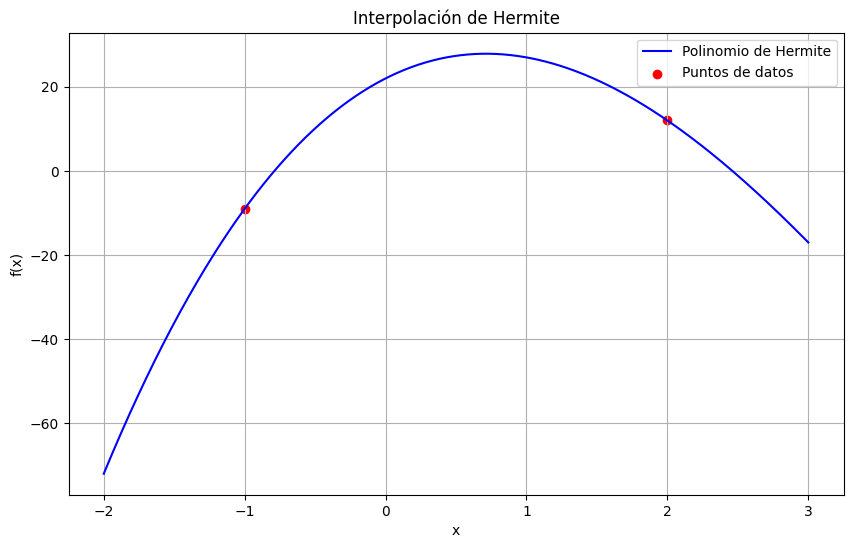

Ingrese valores exponenciales separados por comas (ejemplo: 1, 2, 3): no


ValueError: could not convert string to float: 'no'

In [39]:
#polinomios de Hermite
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

def hermite_interpolation(x_points, y_points, dy_points):
    n = len(x_points)
    # Crear el símbolo de la variable
    x = sp.symbols('x')

    # Inicializar el polinomio de Hermite
    H = 0

    for i in range(n):
        # Inicializar el término del polinomio de Hermite
        term = 1
        for j in range(n):
            if j != i:
                term *= (x - x_points[j]) / (x_points[i] - x_points[j])  # Factor de Lagrange

        # Agregar el término de f(x_i)
        H += y_points[i] * term

        # Agregar el término de f'(x_i)
        term_prime = dy_points[i]
        for j in range(n):
            if j != i:
                term_prime *= (x - x_points[j]) / (x_points[i] - x_points[j])

        H += term_prime * (x - x_points[i])**2

    return sp.simplify(H)

# Solicitar datos al usuario
n = int(input("Ingrese el número de puntos (n): "))
x_points = []
y_points = []
dy_points = []

for i in range(n):
    x = float(input(f"Ingrese x[{i}]: "))
    y = float(input(f"Ingrese f(x[{i}]): "))
    dy = float(input(f"Ingrese f'({x}): "))
    x_points.append(x)
    y_points.append(y)
    dy_points.append(dy)

# Calcular el polinomio de Hermite
hermite_poly = hermite_interpolation(x_points, y_points, dy_points)

# Mostrar el polinomio
print("\nEl polinomio de Hermite es:")
sp.init_printing(use_unicode=True)
sp.pretty_print(hermite_poly)

# Crear un rango de valores para graficar
x_vals = np.linspace(min(x_points) - 1, max(x_points) + 1, 500)
y_vals = [hermite_poly.subs(sp.symbols('x'), x).evalf() for x in x_vals]

# Graficar
plt.figure(figsize=(10, 6))
plt.plot(x_vals, y_vals, label='Polinomio de Hermite', color='blue')
plt.scatter(x_points, y_points, color='red', label='Puntos de datos')
plt.title('Interpolación de Hermite')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.legend()
plt.grid()
plt.show()

# Evaluar en valores exponenciales
exp_values = input("Ingrese valores exponenciales separados por comas (ejemplo: 1, 2, 3): ")
exp_values = [float(val) for val in exp_values.split(",")]

for exp in exp_values:
    result = hermite_poly.subs(sp.symbols('x'), np.exp(exp)).evalf()
    print(f"H(e^{exp}) = {result}")



Tabla de Resultados:
   X  Y Observado  Y Predicho  Error
0  1            2         1.2    0.8
1  2            3         3.4   -0.4
2  3            5         5.6   -0.6
3  4            7         7.8   -0.8
4  5           11        10.0    1.0

Estadísticas del modelo:
Modelo de regresión ajustado: Y = -1.00 + 2.20X
Desviación estándar del error: 0.8367
Varianza del error: 0.7000
Error cuadrático medio (MSE): 0.5600


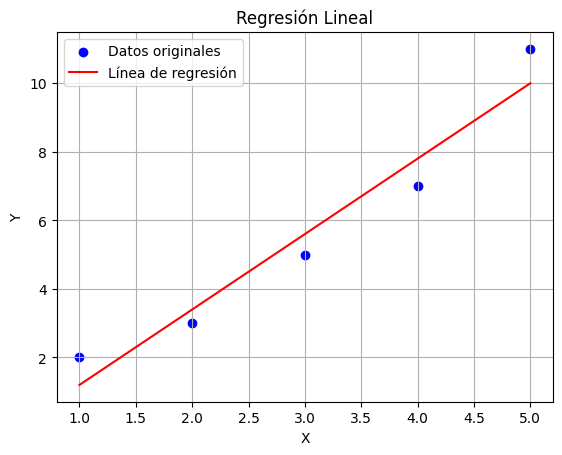

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Datos de ejemplo
X = np.array([1, 2, 3, 4, 5])
Y = np.array([2, 3, 5, 7, 11])

# Calcular los coeficientes de la regresión
n = len(X)
b1 = (n * np.sum(X * Y) - np.sum(X) * np.sum(Y)) / (n * np.sum(X ** 2) - (np.sum(X) ** 2))
b0 = (np.sum(Y) - b1 * np.sum(X)) / n

# Predicciones
Y_pred = b0 + b1 * X

# Calcular la varianza y la desviación estándar del error
error = Y - Y_pred
varianza = np.var(error, ddof=1)  # ddof=1 para la varianza muestral
desviacion_estandar = np.sqrt(varianza)

# Calcular el error cuadrático medio (MSE)
mse = np.mean(error ** 2)

# Crear un DataFrame para mostrar los resultados
resultados = pd.DataFrame({
    'X': X,
    'Y Observado': Y,
    'Y Predicho': Y_pred,
    'Error': error,
})

# Mostrar los resultados
print("Tabla de Resultados:")
print(resultados)

# Mostrar estadísticas
print("\nEstadísticas del modelo:")
print(f"Modelo de regresión ajustado: Y = {b0:.2f} + {b1:.2f}X")
print(f"Desviación estándar del error: {desviacion_estandar:.4f}")
print(f"Varianza del error: {varianza:.4f}")
print(f"Error cuadrático medio (MSE): {mse:.4f}")

# Graficar los resultados
plt.scatter(X, Y, color='blue', label='Datos originales')
plt.plot(X, Y_pred, color='red', label='Línea de regresión')
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Regresión Lineal')
plt.legend()
plt.grid()
plt.show()


Ingresa los valores de X separados por comas: 55,98,77,62,50,95,62,71
Ingresa los valores de Y separados por comas: 163,170,179,182,158,175,183,172

Tabla de Resultados:
      X  Y Observado  Y Predicho      Error
0  55.0        163.0  170.478177  -7.478177
1  98.0        170.0  176.489770  -6.489770
2  77.0        179.0  173.553876   5.446124
3  62.0        182.0  171.456808  10.543192
4  50.0        158.0  169.779154 -11.779154
5  95.0        175.0  176.070357  -1.070357
6  62.0        183.0  171.456808  11.543192
7  71.0        172.0  172.715049  -0.715049

Estadísticas del modelo:
Modelo de regresión ajustado: Y = 162.79 + 0.14X
Desviación estándar del error: 8.5566
Varianza del error: 73.2157
Error cuadrático medio (MSE): 64.0638


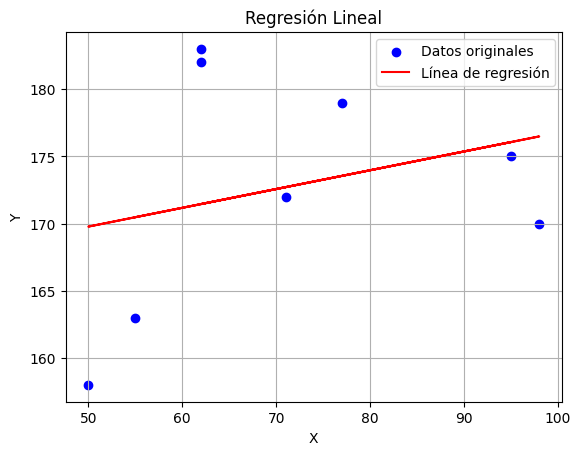

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Función para obtener datos del usuario
def obtener_datos():
    X = input("Ingresa los valores de X separados por comas: ")
    Y = input("Ingresa los valores de Y separados por comas: ")

    # Convertir las entradas en listas de números
    X = np.array([float(i) for i in X.split(',')])
    Y = np.array([float(i) for i in Y.split(',')])

    return X, Y

# Obtener los datos
X, Y = obtener_datos()

# Calcular los coeficientes de la regresión
n = len(X)
b1 = (n * np.sum(X * Y) - np.sum(X) * np.sum(Y)) / (n * np.sum(X ** 2) - (np.sum(X) ** 2))
b0 = (np.sum(Y) - b1 * np.sum(X)) / n

# Predicciones
Y_pred = b0 + b1 * X

# Calcular la varianza y la desviación estándar del error
error = Y - Y_pred
varianza = np.var(error, ddof=1)  # ddof=1 para la varianza muestral
desviacion_estandar = np.sqrt(varianza)

# Calcular el error cuadrático medio (MSE)
mse = np.mean(error ** 2)

# Crear un DataFrame para mostrar los resultados
resultados = pd.DataFrame({
    'X': X,
    'Y Observado': Y,
    'Y Predicho': Y_pred,
    'Error': error,
})

# Mostrar los resultados
print("\nTabla de Resultados:")
print(resultados)

# Mostrar estadísticas
print("\nEstadísticas del modelo:")
print(f"Modelo de regresión ajustado: Y = {b0:.2f} + {b1:.2f}X")
print(f"Desviación estándar del error: {desviacion_estandar:.4f}")
print(f"Varianza del error: {varianza:.4f}")
print(f"Error cuadrático medio (MSE): {mse:.4f}")

# Graficar los resultados
plt.scatter(X, Y, color='blue', label='Datos originales')
plt.plot(X, Y_pred, color='red', label='Línea de regresión')
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Regresión Lineal')
plt.legend()
plt.grid()
plt.show()
